# 10_03 ROC and Precision-Recall Curves, and AUC as a Probability

**Learning objectives**
- Build the **ROC curve** (TPR against FPR over all thresholds) and the **precision-recall (PR) curve** from two score distributions and from data.
- Prove that **AUC $=P(S_1>S_0)$**, equals the **Mann-Whitney U** statistic divided by $n_1n_0$, and for equal-variance Gaussian scores $\mathrm{AUC}=\Phi(d'/\sqrt2)$; relate the Gini coefficient and the KS statistic to it.
- Explain why **ROC is insensitive to prevalence while PR is not**, and why two models with the same AUC can be very different at the operating points that matter (partial AUC).
- Compute and bootstrap AUC, average precision and operating points on real data.

**Prerequisites:** [10_01](10_01_confusion_matrix_from_distributions.ipynb), [10_02](10_02_classification_metrics.ipynb), [05_04 Bootstrap](../../module_05_sampling/notebooks/05_04_bootstrap.ipynb), [09_03 Naive Bayes](../../module_09_probabilistic_models/notebooks/09_03_naive_bayes.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
Each threshold $t$ gives a point $(\mathrm{FPR}(t),\mathrm{TPR}(t))$ with $\mathrm{TPR}(t)=P(S>t\mid1)$ and $\mathrm{FPR}(t)=P(S>t\mid0)$ (10_01). Precision is $\frac{\pi\,\mathrm{TPR}}{\pi\,\mathrm{TPR}+(1-\pi)\mathrm{FPR}}$. The rank-sum (Mann-Whitney) statistic counts the pairs (positive, negative) in which the positive scores higher. The bootstrap resamples cases to get the sampling variability of any statistic.

## 3. Intuition and story
A classifier produces scores; you choose the threshold later, and the threshold depends on costs and capacity that may change. The **ROC curve** shows *every* operating point the scorer offers at once: sweep the threshold from high (flag nothing, bottom-left) to low (flag everything, top-right). A scorer that ranks perfectly hugs the top-left corner; a random one follows the diagonal. The **area under the curve** collapses the whole curve into one number with a clean meaning: pick a random positive and a random negative; AUC is the chance that the positive has the higher score. It measures **ranking quality**, independent of the threshold and of the prevalence. The **PR curve** plots precision against recall instead and exposes what the ROC hides when positives are rare: a tiny FPR can still be a large number of false alarms.

## 4. Formal definitions

| Object | Definition |
|---|---|
| ROC curve | $\{(\mathrm{FPR}(t),\mathrm{TPR}(t)) : t\in\mathbb R\}$, with $\mathrm{TPR}=1-F_1(t)$ and $\mathrm{FPR}=1-F_0(t)$ |
| **AUC** | $\displaystyle\int_0^1 \mathrm{TPR}\,d\mathrm{FPR}=P(S_1>S_0)+\tfrac12P(S_1=S_0)$ |
| Gini coefficient | $2\,\mathrm{AUC}-1$ |
| KS statistic | $\max_t|F_0(t)-F_1(t)|=\max_t(\mathrm{TPR}-\mathrm{FPR})=J_{\max}$ |
| PR curve | $\{(\mathrm{recall}(t),\mathrm{precision}(t))\}$ |
| **Average precision** | $\mathrm{AP}=\sum_k(R_k-R_{k-1})P_k$ (step-wise area under the PR curve) |
| Partial AUC | $\int_0^{f_0}\mathrm{TPR}\,d\mathrm{FPR}$ for a small $f_0$ |
| Binormal ROC | $S_0\sim N(0,1)$, $S_1\sim N(\mu,\sigma^2)$: $\mathrm{TPR}=\Phi\!\big(\frac{\mu+\Phi^{-1}(\mathrm{FPR})}{\sigma}\big)$ |

## 5. Derivations

### 5.1 AUC is the probability that a positive outranks a negative
Write $\mathrm{FPR}(t)=1-F_0(t)$, $\mathrm{TPR}(t)=1-F_1(t)$. Substituting $u=\mathrm{FPR}(t)$, $du=-f_0(t)\,dt$: $\mathrm{AUC}=\int \mathrm{TPR}(t)f_0(t)\,dt=\int P(S_1>t)f_0(t)\,dt=P(S_1>S_0)$, with $S_1,S_0$ independent. **In plain words.** Draw one positive and one negative at random: the AUC is how often the positive scores higher; 0.5 means a coin flip, 1 means perfect ranking.

### 5.2 AUC from ranks (Mann-Whitney)
Counting pairs, $\widehat{\mathrm{AUC}}=\frac{1}{n_1n_0}\sum_{i\in 1}\sum_{j\in 0}\big[\mathbf 1(s_i>s_j)+\tfrac12\mathbf 1(s_i=s_j)\big]=\frac{R_1-n_1(n_1+1)/2}{n_1n_0}$, where $R_1$ is the sum of the ranks of the positives. **In plain words.** The AUC needs only the ranking of the scores, so any increasing transformation of the scores leaves it unchanged.

### 5.3 AUC for Gaussian scores
For $S_0\sim N(0,1)$, $S_1\sim N(\mu,\sigma^2)$: $S_1-S_0\sim N(\mu,1+\sigma^2)$, so $\mathrm{AUC}=P(S_1-S_0>0)=\Phi\!\big(\mu/\sqrt{1+\sigma^2}\big)$; with equal variances ($\sigma=1$, $\mu=d'$) this is $\Phi(d'/\sqrt2)$. **In plain words.** $d'=1.81$ is needed for an AUC of 0.90; $d'=3$ gives 0.983.

### 5.4 The ROC does not depend on prevalence; the PR curve does
TPR and FPR condition on the true class, so the prevalence $\pi$ cancels. Precision does not: $\mathrm{precision}=\frac{\pi\,\mathrm{TPR}}{\pi\,\mathrm{TPR}+(1-\pi)\mathrm{FPR}}$. At fixed recall, precision falls to zero as $\pi\to0$. **In plain words.** The ROC says how good the scorer is at separating the classes; the PR curve says how useful it is *at this base rate*.

### 5.5 Slopes and the optimal points
The slope of the ROC curve at a threshold is the likelihood ratio $f_1(t)/f_0(t)$. A threshold that minimises a cost sits where the slope equals $\frac{c_{FP}(1-\pi)}{c_{FN}\pi}$ (next lesson). A **concave** ROC curve corresponds to a monotone likelihood ratio; a curve that dips below its chord means the score is not calibrated for ranking in that region. **In plain words.** Moving along the curve is moving the threshold; the steepness tells how many extra hits one more false alarm buys.

### 5.6 Why AUC can mislead
Two ROC curves can cross: one scorer is better at strict thresholds (low FPR), the other at lenient ones, with the same total area. AUC is also blind to calibration (a monotone transformation does not change it) and to the cost structure. **In plain words.** AUC averages over operating points you will never use; look at the part of the curve that matches your capacity (the partial AUC) or at the PR curve.

## 6. Properties and relationships
- **Invariance:** AUC is unchanged by any strictly increasing transformation of the scores and by changes of the prevalence.
- **Gini and KS:** $\mathrm{Gini}=2\mathrm{AUC}-1$ is the credit-scoring name; $\mathrm{KS}=\max(\mathrm{TPR}-\mathrm{FPR})$ is Youden's $J_{\max}$ (10_02).
- **Chance and inversion:** AUC $<0.5$ means the scores are anti-correlated with the label; flipping the sign gives $1-\mathrm{AUC}$.
- **AP and PR:** AP summarises the PR curve; its chance level is the prevalence $\pi$, not 0.5.
- **Variance:** $\mathrm{Var}(\widehat{\mathrm{AUC}})$ shrinks like $1/n_1+1/n_0$; the number of positives dominates (DeLong's estimator and the bootstrap).
- **Link to ML and AI:** AUC is the standard summary for rankers, retrieval and recommendation (together with precision at $k$), safety classifiers and out-of-distribution detectors (AUROC), and for comparing models in credit scoring and medicine.

## 7. ROC and PR toolkit

Empirical ROC and PR curves from scores (with ties handled), the Mann-Whitney AUC, the theoretical binormal ROC, and average precision.

In [2]:
def roc_emp(s, y):
    o = np.argsort(-s, kind="mergesort"); s_, y_ = s[o], y[o]; tps = np.cumsum(y_); fps = np.cumsum(1 - y_); last = np.r_[np.where(np.diff(s_))[0], len(s_) - 1]
    return np.r_[0, fps[last] / fps[-1]], np.r_[0, tps[last] / tps[-1]], np.r_[np.inf, s_[last]]
def auc_mw(s, y):
    r = stats.rankdata(s); n1 = int(y.sum()); n0 = len(y) - n1; return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
def pr_emp(s, y):
    o = np.argsort(-s, kind="mergesort"); s_, y_ = s[o], y[o]; tps = np.cumsum(y_); fps = np.cumsum(1 - y_); last = np.r_[np.where(np.diff(s_))[0], len(s_) - 1]
    prec = tps[last] / (tps[last] + fps[last]); rec = tps[last] / tps[-1]; return rec, prec
def avg_prec(s, y):
    rec, prec = pr_emp(s, y); return float(np.sum(np.diff(np.r_[0, rec]) * prec))
def binorm_roc(f, mu, sig=1.0): return stats.norm.cdf((mu + stats.norm.ppf(f)) / sig)
def auc_binorm(mu, sig=1.0): return stats.norm.cdf(mu / np.sqrt(1 + sig ** 2))
g = np.random.default_rng(0); s_ = np.r_[g.normal(0, 1, 3000), g.normal(1.5, 1, 1000)]; y_ = np.r_[np.zeros(3000), np.ones(1000)].astype(int); f, t, _ = roc_emp(s_, y_)
print("AUC: trapezoid", round(float(np.trapezoid(t, f)), 4), "| Mann-Whitney", round(float(auc_mw(s_, y_)), 4), "| theory Phi(d'/sqrt 2)", round(float(auc_binorm(1.5)), 4), "| average precision", round(avg_prec(s_, y_), 4), "(chance level = prevalence 0.25)")
assert abs(np.trapezoid(t, f) - auc_mw(s_, y_)) < 1e-9 and abs(auc_mw(s_, y_) - auc_binorm(1.5)) < 0.015

AUC: trapezoid 0.8659 | Mann-Whitney 0.8659 | theory Phi(d'/sqrt 2) 0.8556 | average precision 0.7163 (chance level = prevalence 0.25)


## 8. 2D visuals

### 8.1 The ROC curve and the PR curve of the same scorer
$d'=2$. Left: the ROC curve for the theoretical Gaussian model with 20,000 simulated cases overlaid, the diagonal and a few thresholds. Right: PR curves at prevalence 50 %, 10 % and 1 % from the same ROC.

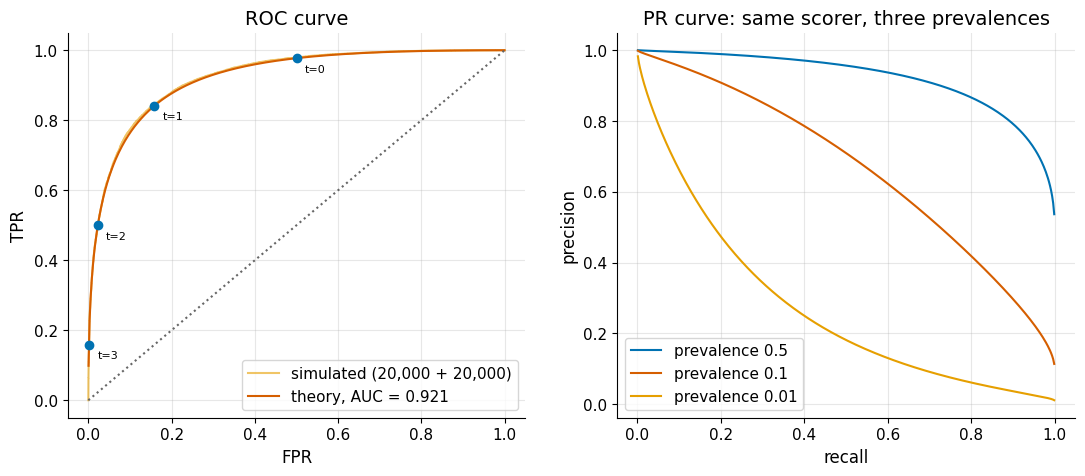

AUC theory 0.9214, Mann-Whitney 0.9234; precision at recall 0.8: {0.5: 0.866, 0.1: 0.419, 0.01: 0.061}


In [3]:
g = np.random.default_rng(1); n1_, n0_ = 20_000, 20_000; sc = np.r_[g.normal(0, 1, n0_), g.normal(2, 1, n1_)]; yy = np.r_[np.zeros(n0_), np.ones(n1_)].astype(int); fe, te, _ = roc_emp(sc, yy); fg_ = np.linspace(0.0005, 0.9995, 400)
fig, axes = plt.subplots(1, 2, figsize=(13, 5)); axes[0].step(fe, te, color=SIM, alpha=0.6, label="simulated (20,000 + 20,000)"); axes[0].plot(fg_, binorm_roc(fg_, 2), color=HIGHLIGHT, label=f"theory, AUC = {auc_binorm(2):.3f}"); axes[0].plot([0, 1], [0, 1], color=NEUTRAL, linestyle=":")
for th in (0, 1, 2, 3): axes[0].plot(stats.norm.sf(th), stats.norm.sf(th - 2), "o", color=MAIN); axes[0].annotate(f"t={th}", (stats.norm.sf(th), stats.norm.sf(th - 2)), xytext=(6, -10), textcoords="offset points", fontsize=8)
axes[0].legend(); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].set_title("ROC curve")
rr = np.linspace(0.001, 0.999, 400); fr = stats.norm.sf(stats.norm.isf(rr) + 2)  # FPR at the threshold where TPR = rr: TPR = sf(t - 2) -> t = 2 + isf(rr); FPR = sf(t)
for p, c in [(0.5, MAIN), (0.1, HIGHLIGHT), (0.01, SIM)]: axes[1].plot(rr, p * rr / (p * rr + (1 - p) * fr), color=c, label=f"prevalence {p}")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].legend(); axes[1].set_title("PR curve: same scorer, three prevalences")
plt.show(); print("AUC theory %.4f, Mann-Whitney %.4f; precision at recall 0.8: %s" % (auc_binorm(2), auc_mw(sc, yy), {p: round(float(p * 0.8 / (p * 0.8 + (1 - p) * stats.norm.sf(stats.norm.isf(0.8) + 2))), 3) for p in (0.5, 0.1, 0.01)})); assert abs(auc_mw(sc, yy) - auc_binorm(2)) < 0.005

### 8.2 AUC as a function of separability
The AUC as a function of $d'$ for equal variances, with the simulated Mann-Whitney AUC at several $d'$; and the AUC when the positive scores are more spread out ($\sigma=0.5,1,2$).

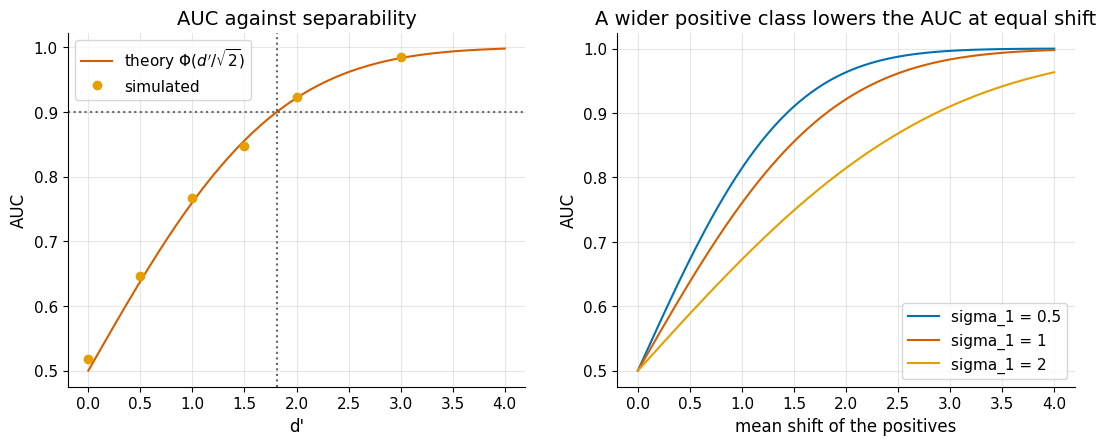

d' for AUC 0.9: 1.8124 | simulated vs theory: [(0.0, 0.518, 0.5), (0.5, 0.645, 0.638), (1.0, 0.767, 0.76), (1.5, 0.847, 0.856), (2.0, 0.923, 0.921), (3.0, 0.984, 0.983)]


In [4]:
ds = np.linspace(0, 4, 200); g = np.random.default_rng(2); dd = np.array([0, 0.5, 1, 1.5, 2, 3]); sim = []
for d in dd: s_ = np.r_[g.normal(0, 1, 4000), g.normal(d, 1, 4000)]; y_ = np.r_[np.zeros(4000), np.ones(4000)].astype(int); sim.append(auc_mw(s_, y_))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); axes[0].plot(ds, auc_binorm(ds), color=HIGHLIGHT, label=r"theory $\Phi(d'/\sqrt{2})$"); axes[0].plot(dd, sim, "o", color=SIM, label="simulated"); axes[0].axhline(0.9, color=NEUTRAL, linestyle=":"); axes[0].axvline(np.sqrt(2) * stats.norm.ppf(0.9), color=NEUTRAL, linestyle=":"); axes[0].legend(); axes[0].set_xlabel("d'"); axes[0].set_ylabel("AUC"); axes[0].set_title("AUC against separability")
for sg, c in [(0.5, MAIN), (1, HIGHLIGHT), (2, SIM)]: axes[1].plot(ds, auc_binorm(ds, sg), color=c, label=f"sigma_1 = {sg}")
axes[1].legend(); axes[1].set_xlabel("mean shift of the positives"); axes[1].set_ylabel("AUC"); axes[1].set_title("A wider positive class lowers the AUC at equal shift")
plt.show(); print("d' for AUC 0.9:", round(float(np.sqrt(2) * stats.norm.ppf(0.9)), 4), "| simulated vs theory:", [(float(a), round(float(b), 3), round(float(auc_binorm(a)), 3)) for a, b in zip(dd, sim)]); assert max(abs(np.array(sim) - auc_binorm(dd))) < 0.02

### 8.3 ROC is blind to prevalence; PR is not
Same scorer ($d'=2$) at prevalence 50 %, 5 % and 0.5 %: the empirical ROC curves coincide, the PR curves drift down, and the average precision falls towards the prevalence.

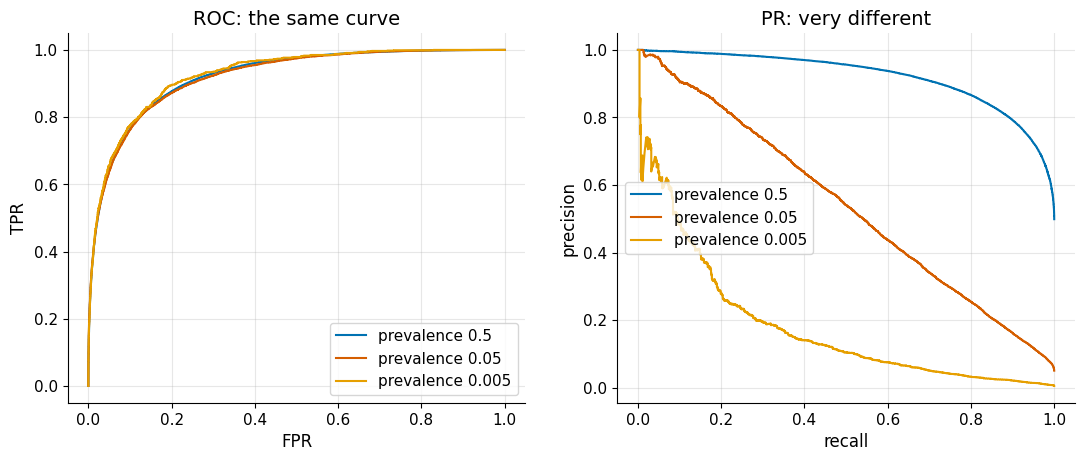

{0.5: (np.float64(0.9217), 0.9215), 0.05: (np.float64(0.9195), 0.54), 0.005: (np.float64(0.9262), 0.1793)}


In [5]:
g = np.random.default_rng(3); fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); out = {}
for p, c in [(0.5, MAIN), (0.05, HIGHLIGHT), (0.005, SIM)]:
    n = 200_000; y_ = (g.random(n) < p).astype(int); s_ = np.where(y_ == 1, g.normal(2, 1, n), g.normal(0, 1, n)); f_, t_, _ = roc_emp(s_, y_); r_, pr_ = pr_emp(s_, y_); out[p] = (auc_mw(s_, y_), avg_prec(s_, y_)); axes[0].plot(f_, t_, color=c, label=f"prevalence {p}"); axes[1].plot(r_, pr_, color=c, label=f"prevalence {p}")
axes[0].legend(); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].set_title("ROC: the same curve"); axes[1].legend(); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_title("PR: very different")
plt.show(); print({p: (round(a, 4), round(b, 4)) for p, (a, b) in out.items()}); assert max(abs(a - out[0.5][0]) for a, _ in out.values()) < 0.005 and out[0.005][1] < 0.2 < out[0.5][1] - 0.2

## 9. 3D visuals

### 9.1 Static: the ROC surface over (FPR, $d'$)
For each separability $d'$ the ROC curve is a slice of this surface; the surface rises from the diagonal ($d'=0$) towards the top-left corner.

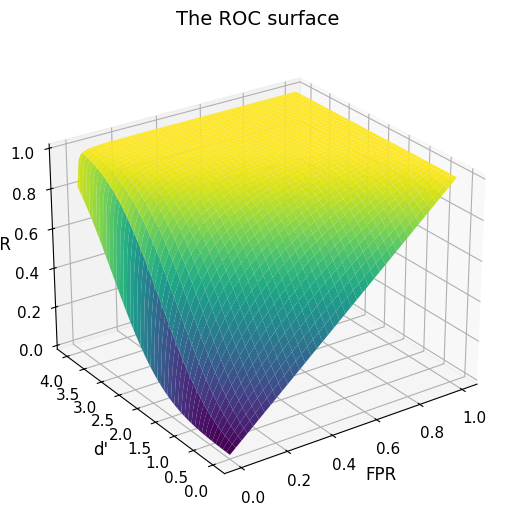

TPR at FPR 0.1 for d' = 0, 1, 2, 3: [0.1, 0.389, 0.764, 0.957]


In [6]:
Fg, Dg = np.meshgrid(np.linspace(0.001, 0.999, 120), np.linspace(0, 4, 90)); Z = stats.norm.cdf(Dg + stats.norm.ppf(Fg))
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Fg, Dg, Z, cmap="viridis", edgecolor="none"); ax.set_xlabel("FPR"); ax.set_ylabel("d'"); ax.set_zlabel("TPR"); ax.set_title("The ROC surface"); ax.view_init(elev=26, azim=-125)
plt.show(); print("TPR at FPR 0.1 for d' = 0, 1, 2, 3:", [round(float(stats.norm.cdf(d + stats.norm.ppf(0.1))), 3) for d in (0, 1, 2, 3)]); assert abs(Z[0, 60] - Fg[0, 60]) < 1e-9 and Z[-1, 60] > 0.99

### 9.2 Interactive Plotly version
Rotate to compare the shape at low and high $d'$.

In [7]:
fig = go.Figure(go.Surface(x=Fg[0], y=Dg[:, 0], z=Z, colorscale="Viridis")); fig.update_layout(title="ROC surface: TPR over (FPR, d')", width=760, height=560, scene=dict(xaxis_title="FPR", yaxis_title="d'", zaxis_title="TPR")); fig.show()

### 9.3 Static: precision over (recall, prevalence)
For $d'=2$: at a fixed recall the precision falls steeply as the prevalence drops; the top ridge near prevalence 1 disappears for rare events (log axis).

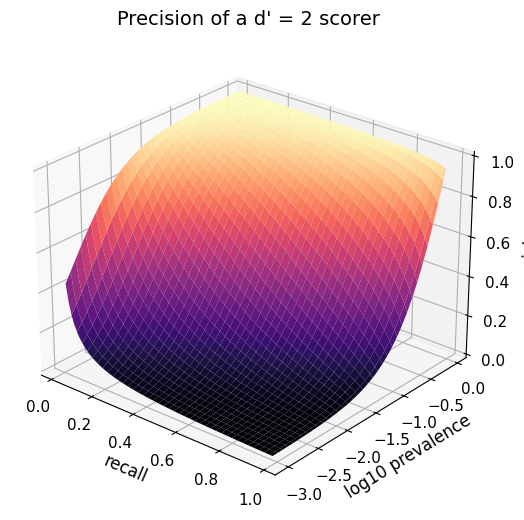

precision at recall 0.8 for prevalence 0.5 / 0.1 / 0.01 / 0.001: [0.865, 0.427, 0.06, 0.007]


In [8]:
Rg, Pg = np.meshgrid(np.linspace(0.02, 0.98, 80), np.linspace(-3, -0.05, 70)); pv = 10 ** Pg; Fr = stats.norm.sf(stats.norm.isf(Rg) + 2); Pr = pv * Rg / (pv * Rg + (1 - pv) * Fr)
fig = plt.figure(figsize=(9, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Rg, Pg, Pr, cmap="magma", edgecolor="none"); ax.set_xlabel("recall"); ax.set_ylabel("log10 prevalence"); ax.set_zlabel("precision"); ax.set_title("Precision of a d' = 2 scorer"); ax.view_init(elev=26, azim=-50)
plt.show(); i80 = np.argmin(np.abs(Rg[0] - 0.8)); print("precision at recall 0.8 for prevalence 0.5 / 0.1 / 0.01 / 0.001:", [round(float(Pr[np.argmin(np.abs(Pg[:, 0] - np.log10(p))), i80]), 3) for p in (0.5, 0.1, 0.01, 0.001)]); assert Pr[-1, i80] > 0.8 and Pr[0, i80] < 0.01

## 10. Simulation vs theory

### 10.1 AUC is $P(S_1>S_0)$, and the variance of the estimator
Draw 1,000 evaluation sets with $n_1=n_0=100$ for $d'=1.5$: the mean of the Mann-Whitney AUC equals $\Phi(d'/\sqrt2)$, the SD matches the Hanley-McNeil formula, and a direct pairwise comparison gives the same value as the rank formula.

In [9]:
g = np.random.default_rng(4); A = auc_binorm(1.5); vals = []
for _ in range(1000): s0, s1 = g.normal(0, 1, 100), g.normal(1.5, 1, 100); vals.append(auc_mw(np.r_[s0, s1], np.r_[np.zeros(100), np.ones(100)].astype(int)))
q1, q2 = A / (2 - A), 2 * A ** 2 / (1 + A); hm = np.sqrt((A * (1 - A) + 99 * (q1 - A ** 2) + 99 * (q2 - A ** 2)) / 100 ** 2)
s0, s1 = g.normal(0, 1, 500), g.normal(1.5, 1, 500); pair = np.mean(s1[:, None] > s0[None, :]); print(f"mean AUC {np.mean(vals):.4f} (theory {A:.4f}) | SD {np.std(vals):.4f} (Hanley-McNeil {hm:.4f}) | pairwise {pair:.4f} vs ranks {auc_mw(np.r_[s0, s1], np.r_[np.zeros(500), np.ones(500)].astype(int)):.4f}")
assert abs(np.mean(vals) - A) < 0.004 and abs(np.std(vals) - hm) < 0.004 and abs(pair - auc_mw(np.r_[s0, s1], np.r_[np.zeros(500), np.ones(500)].astype(int))) < 1e-12

mean AUC 0.8566 (theory 0.8556) | SD 0.0257 (Hanley-McNeil 0.0270) | pairwise 0.8608 vs ranks 0.8608


### 10.2 Invariance to monotone transformations
Exponentiating or cubing the scores changes the shape of the distributions but not the ranking: AUC is identical, while a threshold-based metric changes.

In [10]:
s_ = np.r_[g.normal(0, 1, 2000), g.normal(1, 1, 2000)]; y_ = np.r_[np.zeros(2000), np.ones(2000)].astype(int); print({nm: round(float(auc_mw(f_(s_), y_)), 6) for nm, f_ in {"identity": lambda z: z, "exp": np.exp, "cube": lambda z: z ** 3, "sigmoid": lambda z: 1 / (1 + np.exp(-z)), "negated": lambda z: -z}.items()}); assert abs(auc_mw(np.exp(s_), y_) - auc_mw(s_, y_)) < 1e-12 and abs(auc_mw(-s_, y_) - (1 - auc_mw(s_, y_))) < 1e-12

{'identity': 0.746009, 'exp': 0.746009, 'cube': 0.746009, 'sigmoid': 0.746009, 'negated': 0.253991}


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("AUC from ranks: r = stats.rankdata(s); (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0) | same as stats.mannwhitneyu(s1, s0).statistic / (n1 * n0)")
print("binormal: AUC = stats.norm.cdf(mu / np.sqrt(1 + sigma ** 2)); TPR = stats.norm.cdf((mu + stats.norm.ppf(fpr)) / sigma)")
print("library equivalents: sklearn.metrics.roc_curve, roc_auc_score, precision_recall_curve, average_precision_score, auc")
s1 = g.normal(1.5, 1, 300); s0 = g.normal(0, 1, 300); u = stats.mannwhitneyu(s1, s0); print("check:", round(float(u.statistic / (300 * 300)), 6), "=", round(float(auc_mw(np.r_[s0, s1], np.r_[np.zeros(300), np.ones(300)].astype(int))), 6), "| Gini =", round(2 * float(u.statistic / 90000) - 1, 4)); assert abs(u.statistic / 90000 - auc_mw(np.r_[s0, s1], np.r_[np.zeros(300), np.ones(300)].astype(int))) < 1e-12

AUC from ranks: r = stats.rankdata(s); (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0) | same as stats.mannwhitneyu(s1, s0).statistic / (n1 * n0)
binormal: AUC = stats.norm.cdf(mu / np.sqrt(1 + sigma ** 2)); TPR = stats.norm.cdf((mu + stats.norm.ppf(fpr)) / sigma)
library equivalents: sklearn.metrics.roc_curve, roc_auc_score, precision_recall_curve, average_precision_score, auc
check: 0.859611 = 0.859611 | Gini = 0.7192


## 12. Real-world worked examples

---
### Example 1 (main): how much separation does a model need? (AUC, Gini, KS)

**Scenario.** A bank's credit-scorecard team receives models with different separation between defaulters and non-defaulters. Scores are Gaussian with equal variance and $d'=0.5,1,1.5,2,3$. For each: the AUC, the Gini coefficient, the KS statistic and the TPR at an FPR of 5 % and 20 %.

**Questions**
1. Complete the table by theory and by simulation (5,000 + 5,000 cases).
2. What $d'$ is needed for an AUC of 0.90 and for a Gini of 0.60?
3. If the scorecard may reject 20 % of the good customers, what share of defaulters does a $d'=1.5$ model catch?

### 12.1 By hand
$\mathrm{AUC}=\Phi(d'/\sqrt2)$: $d'=1.5$ gives $\Phi(1.0607)=0.856$, Gini $=0.711$. KS $=\max(\mathrm{TPR}-\mathrm{FPR})=2\Phi(d'/2)-1$ (at the threshold $d'/2$): for $d'=1.5$, $2\Phi(0.75)-1=0.547$. TPR at FPR $f$ is $\Phi(d'+\Phi^{-1}(f))$: at $f=0.05$, $\Phi(1.5-1.645)=0.442$; at $f=0.2$, $\Phi(1.5-0.8416)=0.745$. AUC $=0.9$ needs $d'=\sqrt2\,\Phi^{-1}(0.9)=1.812$; Gini $0.6$ means AUC $0.8$, $d'=\sqrt2\,\Phi^{-1}(0.8)=1.190$.

In [12]:
ds = np.array([0.5, 1, 1.5, 2, 3]); th = pd.DataFrame({"AUC": auc_binorm(ds), "Gini": 2 * auc_binorm(ds) - 1, "KS": 2 * stats.norm.cdf(ds / 2) - 1, "TPR at FPR 5%": binorm_roc(0.05, ds), "TPR at FPR 20%": binorm_roc(0.20, ds)}, index=ds); th.index.name = "d'"
g = np.random.default_rng(5); rows = []
for d in ds:
    s_ = np.r_[g.normal(0, 1, 5000), g.normal(d, 1, 5000)]; y_ = np.r_[np.zeros(5000), np.ones(5000)].astype(int); f_, t_, _ = roc_emp(s_, y_); a = auc_mw(s_, y_); rows.append({"AUC": a, "Gini": 2 * a - 1, "KS": float(np.max(t_ - f_)), "TPR at FPR 5%": float(np.interp(0.05, f_, t_)), "TPR at FPR 20%": float(np.interp(0.20, f_, t_))})
si = pd.DataFrame(rows, index=ds); si.index.name = "d'"; print("Q1: theory"); print(th.round(4).to_string()); print("simulation"); print(si.round(4).to_string()); print("Q2: d' for AUC 0.9:", round(float(np.sqrt(2) * stats.norm.ppf(0.9)), 4), "| d' for Gini 0.6 (AUC 0.8):", round(float(np.sqrt(2) * stats.norm.ppf(0.8)), 4)); print("Q3: TPR at FPR 20% for d' = 1.5:", round(float(binorm_roc(0.2, 1.5)), 4))

Q1: theory
        AUC    Gini      KS  TPR at FPR 5%  TPR at FPR 20%
d'                                                        
0.5  0.6382  0.2763  0.1974         0.1261          0.3663
1.0  0.7602  0.5205  0.3829         0.2595          0.5629
1.5  0.8556  0.7112  0.5467         0.4424          0.7449
2.0  0.9214  0.8427  0.6827         0.6388          0.8766
3.0  0.9831  0.9661  0.8664         0.9123          0.9846
simulation
        AUC    Gini      KS  TPR at FPR 5%  TPR at FPR 20%
d'                                                        
0.5  0.6299  0.2597  0.1880         0.1176          0.3536
1.0  0.7633  0.5266  0.3982         0.2630          0.5722
1.5  0.8621  0.7243  0.5728         0.4534          0.7676
2.0  0.9227  0.8454  0.6846         0.6500          0.8782
3.0  0.9835  0.9670  0.8642         0.9118          0.9860
Q2: d' for AUC 0.9: 1.8124 | d' for Gini 0.6 (AUC 0.8): 1.1902
Q3: TPR at FPR 20% for d' = 1.5: 0.7449


### 12.2 Asserts

In [13]:
assert abs(th.loc[1.5, "AUC"] - 0.8556) < 5e-4 and abs(th.loc[1.5, "KS"] - 0.5467) < 5e-4 and abs(th.loc[1.5, "TPR at FPR 5%"] - 0.4424) < 5e-4 and abs(th.loc[1.5, "TPR at FPR 20%"] - 0.7450) < 5e-3 and np.abs((si - th).to_numpy()).max() < 0.03
print("all checks passed")

all checks passed


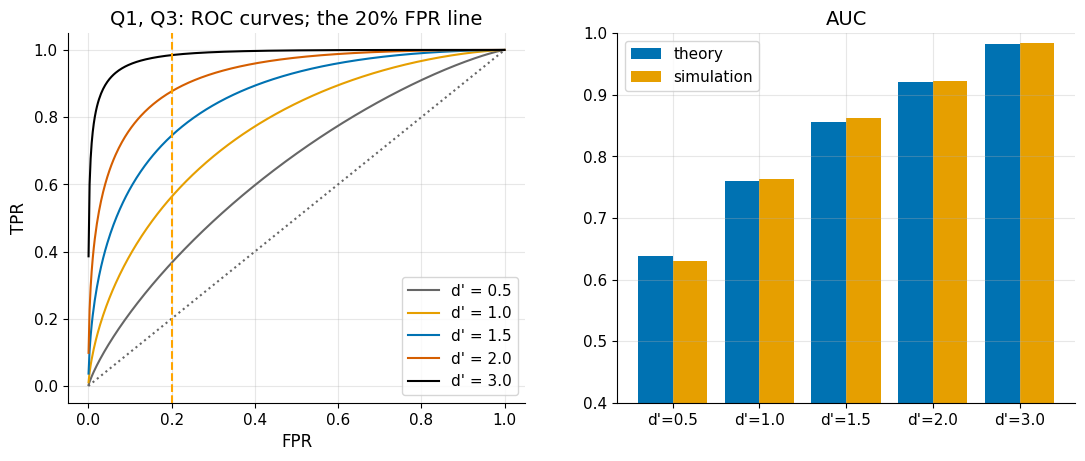

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); fg_ = np.linspace(0.0005, 0.9995, 400)
for d, c in zip(ds, [NEUTRAL, SIM, MAIN, HIGHLIGHT, "black"]): axes[0].plot(fg_, binorm_roc(fg_, d), color=c, label=f"d' = {d}")
axes[0].plot([0, 1], [0, 1], color=NEUTRAL, linestyle=":"); axes[0].axvline(0.2, color="orange", linestyle="--"); axes[0].legend(); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].set_title("Q1, Q3: ROC curves; the 20% FPR line")
x = np.arange(5); axes[1].bar(x - 0.2, th["AUC"], 0.4, color=MAIN, label="theory"); axes[1].bar(x + 0.2, si["AUC"], 0.4, color=SIM, label="simulation"); axes[1].set_xticks(x); axes[1].set_xticklabels([f"d'={d}" for d in ds]); axes[1].set_ylim(0.4, 1); axes[1].legend(); axes[1].set_title("AUC")
plt.show()

### 12.3 Interpretation and decision (Example 1)
- For equal-variance Gaussian scores the AUC is **0.638, 0.760, 0.856, 0.921, 0.983** for $d'=0.5,1,1.5,2,3$ (Gini 0.28, 0.52, 0.71, 0.84, 0.97); 5,000 + 5,000 simulated cases agree within 0.03 on every entry (for example AUC 0.862 against 0.856 at $d'=1.5$).
- The KS statistic equals $2\Phi(d'/2)-1$: **0.547** for $d'=1.5$, reached at the threshold $d'/2=0.75$.
- A model with $d'=1.5$ catches **44.2 %** of the defaulters if only 5 % of the good customers may be rejected and **74.5 %** if 20 % may be rejected.
- An AUC of 0.90 needs $d'=$ **1.812**, a Gini of 0.60 needs $d'=$ **1.190**: halving the remaining error from AUC 0.8 to 0.9 requires moving the classes about 0.6 standard deviations further apart.
- **Decision.** Compare scorecards by AUC or Gini for ranking quality, then read the TPR at the FPR the bank can actually afford: that, not the total area, is what the business gets.

---
### Example 2: the same model, ten times rarer (ROC against PR)

**Scenario.** A content-moderation model with $d'=2$ is deployed on streams where the harmful share is 50 %, 10 %, 1 % and 0.1 %.

**Questions.** (1) AUC and average precision at each prevalence (theory and simulation). (2) The precision at recall 0.8 and the number of reviews per harmful item found. (3) Which curve warns you?

In [15]:
def ap_theory(p, d=2.0):
    r = np.linspace(1e-6, 1 - 1e-6, 200_001); f_ = stats.norm.sf(stats.norm.isf(r) + d); return float(np.trapezoid(p * r / (p * r + (1 - p) * f_), r))
g = np.random.default_rng(6); rows = {}
for p in (0.5, 0.1, 0.01, 0.001):
    n = 400_000; y_ = (g.random(n) < p).astype(int); s_ = np.where(y_ == 1, g.normal(2, 1, n), g.normal(0, 1, n)); pr80 = p * 0.8 / (p * 0.8 + (1 - p) * stats.norm.sf(stats.norm.isf(0.8) + 2)); rows[p] = {"positives": int(y_.sum()), "AUC (sim)": auc_mw(s_, y_), "AUC (theory)": float(auc_binorm(2)), "AP (sim)": avg_prec(s_, y_), "AP (theory)": ap_theory(p), "precision at recall 0.8": float(pr80), "reviews per harmful found": float(1 / pr80)}
tb2 = pd.DataFrame(rows).T; tb2.index.name = "prevalence"; print(tb2.round(4).to_string())

            positives  AUC (sim)  AUC (theory)  AP (sim)  AP (theory)  precision at recall 0.8  reviews per harmful found
prevalence                                                                                                               
0.500        199988.0     0.9211        0.9214    0.9209       0.9218                   0.8664                     1.1542
0.100         39962.0     0.9219        0.9214    0.6663       0.6655                   0.4188                     2.3877
0.010          4087.0     0.9197        0.9214    0.2719       0.2690                   0.0615                    16.2652
0.001           387.0     0.9234        0.9214    0.0571       0.0618                   0.0064                   155.0392


### 12.3 Asserts

In [16]:
assert all(abs(tb2["AUC (sim)"] - tb2["AUC (theory)"]) < 0.01) and all(abs(tb2["AP (sim)"] - tb2["AP (theory)"]) < 0.03) and tb2["AP (theory)"].is_monotonic_decreasing and tb2.loc[0.001, "reviews per harmful found"] > 100
print("all checks passed")

all checks passed


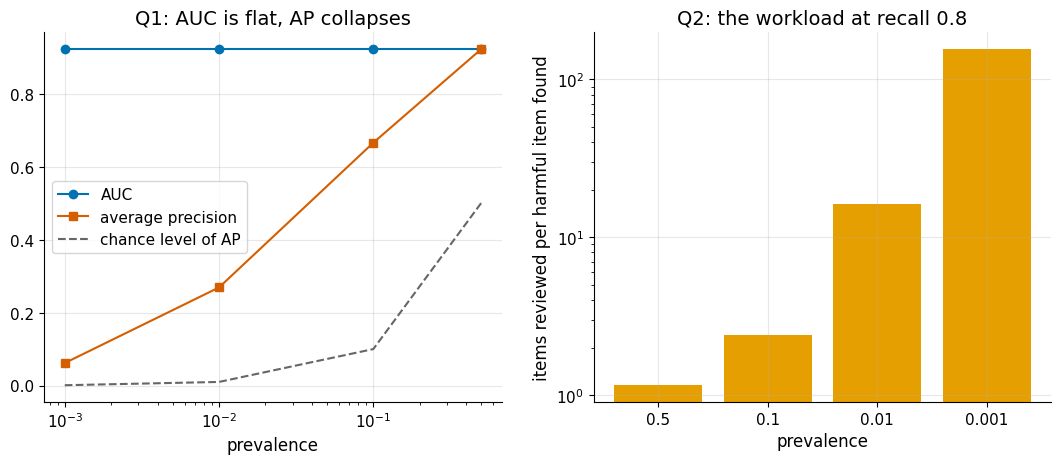

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].semilogx(tb2.index, tb2["AUC (theory)"], "o-", color=MAIN, label="AUC"); axes[0].semilogx(tb2.index, tb2["AP (theory)"], "s-", color=HIGHLIGHT, label="average precision"); axes[0].semilogx(tb2.index, tb2.index, "--", color=NEUTRAL, label="chance level of AP"); axes[0].legend(); axes[0].set_xlabel("prevalence"); axes[0].set_title("Q1: AUC is flat, AP collapses")
axes[1].bar([str(p) for p in tb2.index], tb2["reviews per harmful found"], color=SIM); axes[1].set_yscale("log"); axes[1].set_xlabel("prevalence"); axes[1].set_ylabel("items reviewed per harmful item found"); axes[1].set_title("Q2: the workload at recall 0.8")
plt.show()

### 12.5 Interpretation and decision (Example 2)
- The AUC of the $d'=2$ model is **0.921** at every prevalence (simulated 0.920 to 0.923), whereas the average precision falls from **0.92** (50 %) to **0.67** (10 %), **0.27** (1 %) and **0.06** (0.1 %), close to the chance level of 0.001 only in relative terms: it is 60 times the base rate but still useless in absolute terms.
- At recall 0.8 the precision is **0.866, 0.419, 0.062 and 0.006**, i.e. reviewers must look at **1.2, 2.4, 16 and 155** items per harmful item found.
- **Decision.** The ROC curve (and the AUC) cannot warn you about rare events: always show the PR curve or the precision at the planned recall, computed at the deployment prevalence, and consider a two-stage pipeline when it is low.

---
### Example 3: two scorers, the same AUC, different curves

**Scenario.** Scorer X has equal variances ($\mu_1=1.5$, $\sigma_1=1$). Scorer Y gives positives a wider spread ($\sigma_1=2$) and is calibrated to have the *same* AUC. Which one would you deploy for a team that can review only 1 % of the negatives, and which for one that can review 30 %?

**Questions.** (1) The mean shift of Y that matches X's AUC. (2) The TPR of each at FPR 1 %, 5 %, 30 %. (3) The partial AUC up to FPR 0.1 and the FPR where the curves cross.

In [18]:
aucX = auc_binorm(1.5); muY = stats.norm.ppf(aucX) * np.sqrt(1 + 4); fgr = np.linspace(0.0005, 0.9995, 4000); tX = binorm_roc(fgr, 1.5, 1); tY = binorm_roc(fgr, muY, 2)
pauc = lambda t_, lim: float(np.trapezoid(t_[fgr <= lim], fgr[fgr <= lim])); cross = float(fgr[np.argmin(np.abs(tX - tY)[(fgr > 0.02) & (fgr < 0.9)]) + np.sum(fgr <= 0.02)])
print(f"Q1: AUC X {aucX:.4f}; mean shift of Y {muY:.4f}; AUC Y {auc_binorm(muY, 2):.4f}"); print("Q2:"); print(pd.DataFrame({"X": [binorm_roc(f, 1.5, 1) for f in (0.01, 0.05, 0.30)], "Y": [binorm_roc(f, muY, 2) for f in (0.01, 0.05, 0.30)]}, index=["FPR 1%", "FPR 5%", "FPR 30%"]).round(4).to_string()); print(f"Q3: partial AUC (FPR <= 0.1): X {pauc(tX, 0.1):.4f}, Y {pauc(tY, 0.1):.4f}; the ROC curves cross at FPR {cross:.3f}")
g = np.random.default_rng(7); s0 = g.normal(0, 1, 30_000); sX = g.normal(1.5, 1, 30_000); sY = g.normal(muY, 2, 30_000); yv = np.r_[np.zeros(30_000), np.ones(30_000)].astype(int); aX, aY = auc_mw(np.r_[s0, sX], yv), auc_mw(np.r_[s0, sY], yv); print(f"simulation: AUC X {aX:.4f}, AUC Y {aY:.4f}")

Q1: AUC X 0.8556; mean shift of Y 2.3717; AUC Y 0.8556
Q2:
              X       Y
FPR 1%   0.2043  0.5090
FPR 5%   0.4424  0.6419
FPR 30%  0.8354  0.8222
Q3: partial AUC (FPR <= 0.1): X 0.0410, Y 0.0617; the ROC curves cross at FPR 0.265
simulation: AUC X 0.8557, AUC Y 0.8571


### 12.4 Asserts

In [19]:
assert abs(auc_binorm(muY, 2) - aucX) < 1e-9 and abs(aX - aucX) < 0.006 and abs(aY - aucX) < 0.006 and binorm_roc(0.01, muY, 2) > 2 * binorm_roc(0.01, 1.5, 1) and binorm_roc(0.30, muY, 2) < binorm_roc(0.30, 1.5, 1) and pauc(tY, 0.1) > pauc(tX, 0.1) and 0.05 < cross < 0.5
print("all checks passed")

all checks passed


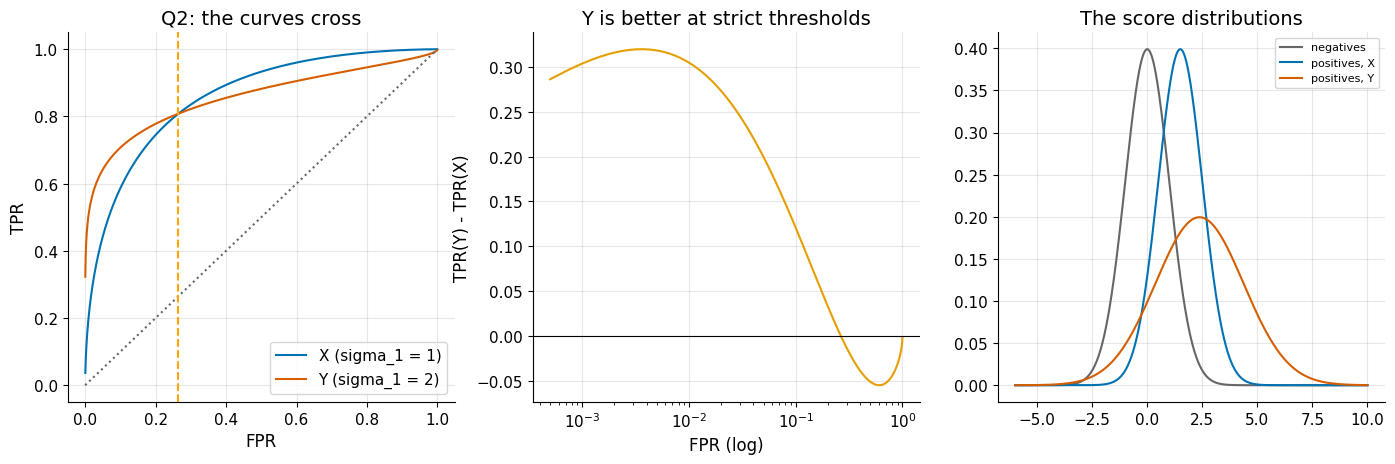

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); axes[0].plot(fgr, tX, color=MAIN, label="X (sigma_1 = 1)"); axes[0].plot(fgr, tY, color=HIGHLIGHT, label="Y (sigma_1 = 2)"); axes[0].plot([0, 1], [0, 1], color=NEUTRAL, linestyle=":"); axes[0].axvline(cross, color="orange", linestyle="--"); axes[0].legend(); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].set_title("Q2: the curves cross")
axes[1].semilogx(fgr, tY - tX, color=SIM); axes[1].axhline(0, color="black", linewidth=0.8); axes[1].set_xlabel("FPR (log)"); axes[1].set_ylabel("TPR(Y) - TPR(X)"); axes[1].set_title("Y is better at strict thresholds")
xs = np.linspace(-6, 10, 600); axes[2].plot(xs, stats.norm.pdf(xs, 0, 1), color=NEUTRAL, label="negatives"); axes[2].plot(xs, stats.norm.pdf(xs, 1.5, 1), color=MAIN, label="positives, X"); axes[2].plot(xs, stats.norm.pdf(xs, muY, 2), color=HIGHLIGHT, label="positives, Y"); axes[2].legend(fontsize=8); axes[2].set_title("The score distributions")
plt.show()

### 12.6 Interpretation and decision (Example 3)
- Y must have its positives centred at **2.372** (with SD 2) to reach the same AUC as X (**0.8556** for both; simulated 0.8557 and 0.8571).
- At an FPR of 1 % scorer Y catches **50.9 %** against **20.4 %** for X, at 5 % **64.2 %** against **44.2 %**, and at 30 % **82.2 %** against **83.5 %**; the curves cross at an FPR of **0.265**. The partial AUC up to an FPR of 0.1 is **0.062 for Y** against **0.041 for X**.
- **Decision.** A team that can review only 1 % to 5 % of the negatives should deploy Y; a team that can accept 30 % or more should prefer X (or either). Equal AUC hid a difference of 30 points of recall at the strict end.

---
### Example 4: ROC and PR on the real SMS spam filter

**Scenario.** The naive Bayes filter of 09_03 scores the 1,115 held-out messages of the SMS Spam Collection (141 spam). A trivial baseline scores each message by its **length in characters** (spam messages tend to be long).

**Questions.** (1) AUC and average precision of the filter and of the length baseline, with 95 % bootstrap intervals. (2) The threshold and false-alarm count at recall 95 % and at precision 95 %. (3) Is the filter's AUC significantly higher than the baseline's (paired bootstrap)?

In [21]:
import re
from collections import Counter
from scipy import sparse
raw = pd.read_csv("../../module_09_probabilistic_models/data/SMSSpamCollection.tsv", sep="\t", header=None, names=["label", "text"], encoding="utf-8", quoting=3); y_all = (raw["label"] == "spam").astype(int).to_numpy(); texts = raw["text"].tolist(); tok = lambda s: re.findall(r"[a-z0-9']+|[£$!?]", s.lower())
g = np.random.default_rng(0); perm = g.permutation(len(texts)); ntr = int(0.8 * len(texts)); itr, ite = perm[:ntr], perm[ntr:]; cnt = Counter(w for i in itr for w in tok(texts[i])); vocab = {w: k for k, (w, c) in enumerate(sorted((w, c) for w, c in cnt.items() if c >= 2))}; V = len(vocab)
def bow(idx):
    rows, cols, vals = [], [], []
    for r, i in enumerate(idx):
        for w, c in Counter(tok(texts[i])).items():
            if w in vocab: rows.append(r); cols.append(vocab[w]); vals.append(c)
    return sparse.csr_matrix((vals, (rows, cols)), shape=(len(idx), V), dtype=float)
Xtr, Xte = bow(itr), bow(ite); ytr, yte = y_all[itr], y_all[ite]; fc = np.vstack([np.asarray(Xtr[ytr == c].sum(axis=0)).ravel() for c in (0, 1)]); lt = np.log((fc + 1) / (fc.sum(axis=1, keepdims=True) + V)); sc = np.asarray(Xte @ (lt[1] - lt[0])).ravel() + np.log(ytr.mean() / (1 - ytr.mean())); ln = np.array([len(texts[i]) for i in ite], dtype=float)
def boot_auc(sa, sb, y, B=2000, seed=0):
    g = np.random.default_rng(seed); out = []
    for _ in range(B): i = g.integers(0, len(y), len(y)); out.append((auc_mw(sa[i], y[i]), auc_mw(sb[i], y[i]), avg_prec(sa[i], y[i]), avg_prec(sb[i], y[i])))
    return np.array(out)
bs = boot_auc(sc, ln, yte); ci = lambda v: f"{np.quantile(v, 0.025):.4f} to {np.quantile(v, 0.975):.4f}"
print(pd.DataFrame({"AUC": [auc_mw(sc, yte), auc_mw(ln, yte)], "AUC 95% interval": [ci(bs[:, 0]), ci(bs[:, 1])], "AP": [avg_prec(sc, yte), avg_prec(ln, yte)], "AP 95% interval": [ci(bs[:, 2]), ci(bs[:, 3])]}, index=["naive Bayes", "message length"]).to_string()); print(f"chance level of AP (prevalence): {yte.mean():.4f}")
f_, t_, th_ = roc_emp(sc, yte); r_, p_ = pr_emp(sc, yte); i95 = np.argmax(t_ >= 0.95); print(f"Q2: recall >= 95%: threshold {th_[i95]:.2f}, FPR {f_[i95]:.4f} = {round(f_[i95] * (yte == 0).sum())} false alarms; ")
o = np.argsort(-sc); tps = np.cumsum(yte[o]); pk = tps / np.arange(1, len(o) + 1); kk = int(np.where(pk >= 0.95)[0].max()); print(f"   precision >= 95%: flag the top {kk + 1} messages, recall {tps[kk] / yte.sum():.3f}")
d = bs[:, 0] - bs[:, 1]; print(f"Q3: AUC difference {auc_mw(sc, yte) - auc_mw(ln, yte):.4f}, 95% interval {np.quantile(d, 0.025):.4f} to {np.quantile(d, 0.975):.4f}")

                    AUC  AUC 95% interval        AP   AP 95% interval
naive Bayes     0.98227  0.9619 to 0.9975  0.972848  0.9487 to 0.9918
message length  0.85998  0.8307 to 0.8871  0.360185  0.3077 to 0.4231
chance level of AP (prevalence): 0.1265
Q2: recall >= 95%: threshold -1.45, FPR 0.0113 = 11 false alarms; 
   precision >= 95%: flag the top 138 messages, recall 0.936
Q3: AUC difference 0.1223, 95% interval 0.0892 to 0.1563


### 12.5 Asserts

In [22]:
assert auc_mw(sc, yte) > 0.97 and auc_mw(ln, yte) < auc_mw(sc, yte) - 0.03 and np.quantile(d, 0.025) > 0 and avg_prec(sc, yte) > 0.9 and avg_prec(ln, yte) > yte.mean()
print("all checks passed")

all checks passed


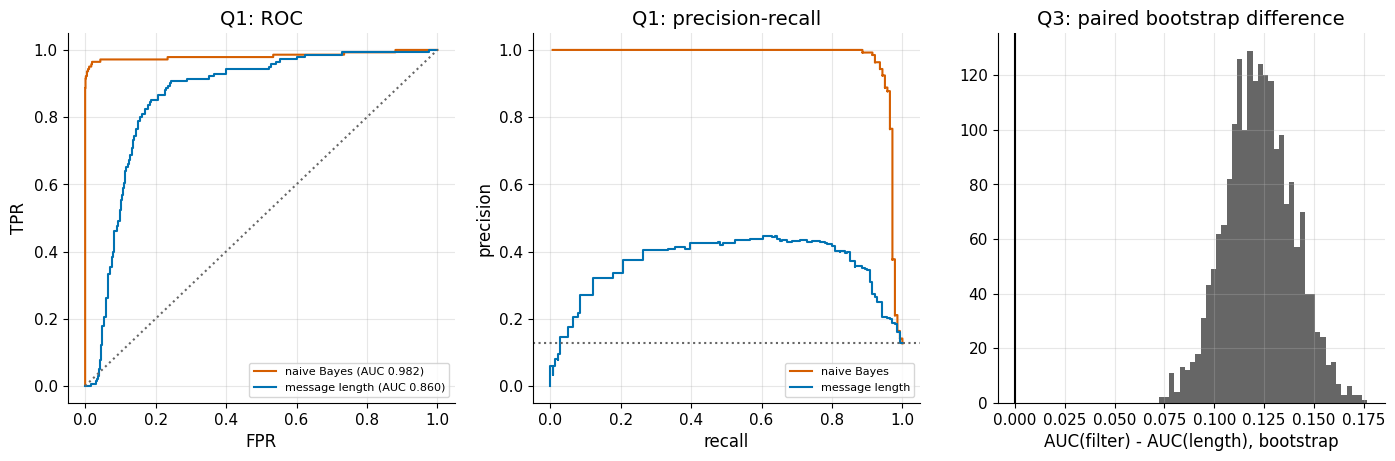

In [23]:
fl, tl, _ = roc_emp(ln, yte); rl, pl = pr_emp(ln, yte); fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); axes[0].step(f_, t_, color=HIGHLIGHT, label=f"naive Bayes (AUC {auc_mw(sc, yte):.3f})"); axes[0].step(fl, tl, color=MAIN, label=f"message length (AUC {auc_mw(ln, yte):.3f})"); axes[0].plot([0, 1], [0, 1], color=NEUTRAL, linestyle=":"); axes[0].legend(fontsize=8); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].set_title("Q1: ROC")
axes[1].step(r_, p_, color=HIGHLIGHT, label="naive Bayes"); axes[1].step(rl, pl, color=MAIN, label="message length"); axes[1].axhline(yte.mean(), color=NEUTRAL, linestyle=":"); axes[1].legend(fontsize=8); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_title("Q1: precision-recall")
axes[2].hist(d, bins=40, color=NEUTRAL); axes[2].axvline(0, color="black"); axes[2].set_xlabel("AUC(filter) - AUC(length), bootstrap"); axes[2].set_title("Q3: paired bootstrap difference")
plt.show()

### 12.8 Interpretation and decision (Example 4)
- On the 1,115 held-out messages the naive Bayes filter has an AUC of **0.982** (95 % interval **0.962 to 0.998**) and an average precision of **0.973** (0.949 to 0.992), against 0.860 (0.831 to 0.887) and 0.360 (chance level 0.127) for the message-length baseline.
- To catch **95 %** of the spam the threshold is **-1.45** with **11 false alarms** (FPR 1.1 %); to keep the precision at **95 %** one can flag the top **138** messages and catch 93.6 % of the spam.
- The paired bootstrap difference in AUC is **0.122** with an interval of **0.089 to 0.156**: the filter is significantly better than the baseline, and the interval stays away from 0 by a wide margin.
- On the training messages the AUC is 0.992 against 0.982 on the test set, a small optimism.
- **Decision.** Report AUC and AP with intervals, choose the operating point from the review capacity or the precision target rather than from the AUC, and always keep a trivial baseline in the comparison.

## 13. Where it is used

### Statistics
- **Diagnostic test evaluation** (ROC analysis, AUC with DeLong intervals), the Mann-Whitney / Wilcoxon rank-sum test (it is the same statistic), the KS statistic, signal detection theory.

### Data science
- **Credit scoring (Gini and KS), fraud and churn ranking, marketing uplift and lead scoring, A/B model comparison, lift and gain charts** (monotone transforms of the ROC), partial AUC for capacity-limited reviews.

### ML and AI
- **AUROC for classifiers, safety and toxicity filters, out-of-distribution and anomaly detectors, membership-inference attacks and AI-text detectors**; average precision and precision at $k$ for retrieval, ranking and object detection (mAP); PR curves for severely imbalanced problems.

## 14. Common pitfalls and misconceptions

- **Thinking AUC measures calibration or the usefulness at one threshold:** it measures ranking only; a transformed or badly calibrated score has the same AUC (10.2, 10_06).
- **Reading a high AUC as a good deployment on rare events:** AUC 0.92 at prevalence 0.1 % still means hundreds of reviews per harmful item (Example 2); look at the PR curve.
- **Comparing AUCs when the curves cross:** use the partial AUC or the operating region that matters (Example 3).
- **Calling an AUC difference real without an interval:** with 141 positives the AUC has a standard error of about 0.01 to 0.02; use bootstrap or DeLong (Example 4).
- **Interpolating PR curves linearly:** the PR curve is not concave and linear interpolation overestimates the area; use the step-wise average precision.
- **Forgetting ties:** many tied scores (rounded probabilities) make the curve a polyline with diagonal pieces; average the ranks (section 7).
- **Using the test set to choose the threshold and then reporting the AUC-based claim:** the threshold is a decision, the AUC is a property of the scorer; choose the threshold on validation data.
- **Believing "AUC below 0.5 is a disaster":** it just means the sign is flipped; check for a leak or an inverted label.

## 15. Exercises

1. Scores: positives $\{0.9,0.8,0.7,0.6,0.4\}$, negatives $\{0.65,0.5,0.35,0.3,0.2,0.1\}$. Compute the AUC by counting pairs and the ROC points.
2. For $d'=2.5$ equal-variance Gaussians find the AUC, the Gini and the KS statistic.
3. A scorer has AUC $0.80$ and the positives have twice the standard deviation of the negatives: what mean shift is that?
4. At prevalence 0.2 %, a scorer reaches TPR 0.9 at FPR 2 %. What is the precision, and how many reviews are needed per positive found?
5. Using the SMS scores of Example 4, compute the AUC of the filter on the *training* messages and compare it with the test AUC.
6. (Harder) Show that if the likelihood ratio $f_1/f_0$ is increasing, the ROC curve is concave, and that the slope at the point with threshold $t$ is $f_1(t)/f_0(t)$.

Solutions are at the end.

## 16. Summary table

| Quantity | Meaning | Depends on prevalence? |
|---|---|---|
| ROC curve | TPR against FPR over all thresholds | no |
| AUC | $P(S_1>S_0)$ = ranking quality; $\Phi(d'/\sqrt2)$ for Gaussians | no |
| Gini, KS | $2\mathrm{AUC}-1$; $\max(\mathrm{TPR}-\mathrm{FPR})$ | no |
| PR curve | precision against recall | yes |
| Average precision | area under the PR curve; chance = prevalence | yes |
| Partial AUC | area up to a small FPR | no |

## Solutions

In [24]:
pos = np.array([0.9, 0.8, 0.7, 0.6, 0.4]); neg = np.array([0.65, 0.5, 0.35, 0.3, 0.2, 0.1]); wins = np.sum(pos[:, None] > neg[None, :]); sx = np.r_[pos, neg]; yx = np.r_[np.ones(5), np.zeros(6)].astype(int); fx, tx, thx = roc_emp(sx, yx); print("1: pairs won", int(wins), "of 30 -> AUC", round(wins / 30, 4), "| rank formula", round(float(auc_mw(sx, yx)), 4), "| ROC points (FPR, TPR):", [(round(float(a), 3), round(float(b), 3)) for a, b in zip(fx, tx)])
print("2: AUC", round(float(auc_binorm(2.5)), 4), "Gini", round(float(2 * auc_binorm(2.5) - 1), 4), "KS", round(float(2 * stats.norm.cdf(1.25) - 1), 4))
print("3: AUC = Phi(mu / sqrt(1 + 4)) = 0.8 -> mu =", round(float(stats.norm.ppf(0.8) * np.sqrt(5)), 4))
prec4 = 0.002 * 0.9 / (0.002 * 0.9 + 0.998 * 0.02); print("4: precision", round(prec4, 4), "-> reviews per positive found", round(1 / prec4, 1))
ytr_score = np.asarray(Xtr @ (lt[1] - lt[0])).ravel() + np.log(ytr.mean() / (1 - ytr.mean())); print("5: training AUC", round(float(auc_mw(ytr_score, ytr)), 4), "| test AUC", round(float(auc_mw(sc, yte)), 4))
print("6: the ROC curve is (u(t), v(t)) = (1 - F0(t), 1 - F1(t)); dv/du = f1(t) / f0(t) = likelihood ratio, decreasing in u when the ratio is increasing in t (u falls as t rises), so the slope falls along the curve and the curve is concave.")
assert abs(wins / 30 - auc_mw(sx, yx)) < 1e-12

1: pairs won 27 of 30 -> AUC 0.9 | rank formula 0.9 | ROC points (FPR, TPR): [(0.0, 0.0), (0.0, 0.2), (0.0, 0.4), (0.0, 0.6), (0.167, 0.6), (0.167, 0.8), (0.333, 0.8), (0.333, 1.0), (0.5, 1.0), (0.667, 1.0), (0.833, 1.0), (1.0, 1.0)]
2: AUC 0.9615 Gini 0.9229 KS 0.7887
3: AUC = Phi(mu / sqrt(1 + 4)) = 0.8 -> mu = 1.8819
4: precision 0.0827 -> reviews per positive found 12.1
5: training AUC 0.9923 | test AUC 0.9823
6: the ROC curve is (u(t), v(t)) = (1 - F0(t), 1 - F1(t)); dv/du = f1(t) / f0(t) = likelihood ratio, decreasing in u when the ratio is increasing in t (u falls as t rises), so the slope falls along the curve and the curve is concave.


**1.** The positive wins in **27 of 30** pairs, so AUC $=0.9$; the ROC points run (0,0), (0,0.2), (0,0.4), (0,0.6), (1/6,0.6), (1/6,0.8), (1/3,0.8), (1/3,1), (1/2,1), ..., (1,1); the rank formula gives the same 0.9.

**2.** $\mathrm{AUC}=\Phi(2.5/\sqrt2)=$ **0.9615**, Gini **0.9229**, KS $=2\Phi(1.25)-1=$ **0.7887**.

**3.** $\Phi(\mu/\sqrt5)=0.8$ gives $\mu=0.8416\sqrt5=$ **1.882**.

**4.** Precision $=\dfrac{0.002\cdot0.9}{0.002\cdot0.9+0.998\cdot0.02}=$ **0.0827**: about **12.1** reviews per positive found.

**5.** The training AUC is **0.9923** against **0.9823** on the test set: the filter is slightly better on the data it was fitted to.

**6.** With $u=1-F_0(t)$ and $v=1-F_1(t)$, $dv/du=f_1(t)/f_0(t)$, the likelihood ratio. As $t$ increases $u$ decreases, so an increasing likelihood ratio means the slope decreases along the curve in the direction of increasing $u$: the curve is concave.